In [556]:
import pandas as pd
import matplotlib as plt
import seaborn as se

df = pd.read_csv(r"C:\Users\thafari\Downloads\archive (1)\Messy_Employee_dataset.csv")

In [557]:
## 1. EDA 

In [558]:
print(df.head())

  Employee_ID First_Name Last_Name   Age   Department_Region    Status  \
0     EMP1000        Bob     Davis  25.0   DevOps-California    Active   
1     EMP1001        Bob     Brown   NaN       Finance-Texas    Active   
2     EMP1002      Alice     Jones   NaN        Admin-Nevada   Pending   
3     EMP1003        Eva     Davis  25.0        Admin-Nevada  Inactive   
4     EMP1004      Frank  Williams  25.0  Cloud Tech-Florida    Active   

    Join_Date     Salary                       Email       Phone  \
0    4/2/2021   59767.65       bob.davis@example.com -1651623197   
1   7/10/2020   65304.66       bob.brown@example.com -1898471390   
2   12/7/2023   88145.90     alice.jones@example.com -5596363211   
3  11/27/2021   69450.99       eva.davis@example.com -3476490784   
4    1/5/2022  109324.61  frank.williams@example.com -1586734256   

  Performance_Score  Remote_Work  
0           Average         True  
1         Excellent         True  
2              Good         True  
3     

In [559]:
df.shape

(1020, 12)

In [560]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   str    
 1   First_Name         1020 non-null   str    
 2   Last_Name          1020 non-null   str    
 3   Age                809 non-null    float64
 4   Department_Region  1020 non-null   str    
 5   Status             1020 non-null   str    
 6   Join_Date          1020 non-null   str    
 7   Salary             996 non-null    float64
 8   Email              1020 non-null   str    
 9   Phone              1020 non-null   int64  
 10  Performance_Score  1020 non-null   str    
 11  Remote_Work        1020 non-null   bool   
dtypes: bool(1), float64(2), int64(1), str(8)
memory usage: 88.8 KB


In [561]:
df.describe()

,Age,Salary,Phone
count,809.000000,996.000000,1.020000e+03
mean,32.484549,85155.056396,-4.942253e+09
std,5.656860,19873.727918,2.817326e+09
min,25.000000,50047.320000,-9.994973e+09
25%,25.000000,68392.487500,-7.341992e+09
50%,30.000000,85547.870000,-4.943997e+09
75%,40.000000,100974.027500,-2.520391e+09
max,40.000000,119971.650000,-3.896086e+06


In [562]:
print(df.isna().sum())


Employee_ID            0
First_Name             0
Last_Name              0
Age                  211
Department_Region      0
Status                 0
Join_Date              0
Salary                24
Email                  0
Phone                  0
Performance_Score      0
Remote_Work            0
dtype: int64


In [563]:
print(df.duplicated().sum())

0


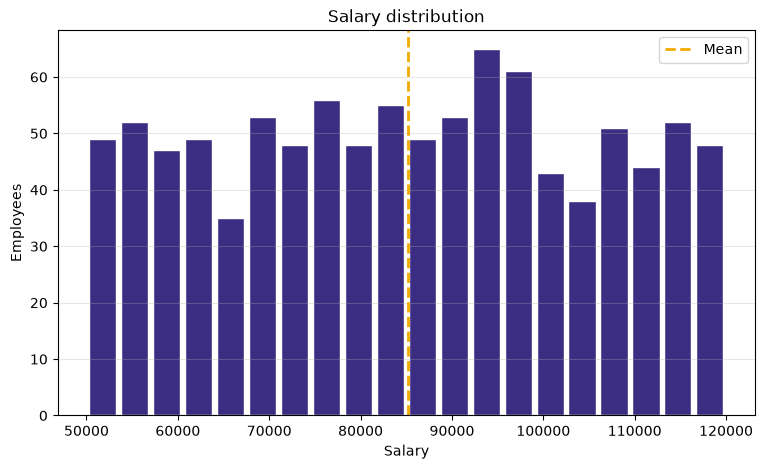

In [564]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.hist(df["Salary"], bins=20, color="#3B2D81", edgecolor="white", rwidth=0.85)
plt.axvline(df["Salary"].mean(), color="#F2A900", linestyle="--", linewidth=2, label="Mean")
plt.title("Salary distribution")
plt.xlabel("Salary")
plt.ylabel("Employees")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("salary_hist.png", dpi=200, bbox_inches="tight")
plt.show()

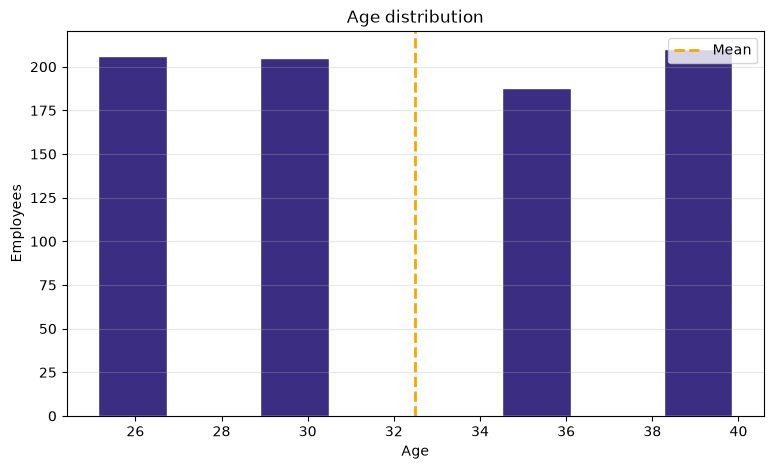

In [565]:
plt.figure(figsize=(9, 5))
plt.hist(df["Age"].dropna(), bins=8, color="#3B2D81", edgecolor="white", rwidth=0.85)
plt.axvline(df["Age"].mean(), color="#F2A900", linestyle="--", linewidth=2, label="Mean")
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Employees")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("age_hist.png", dpi=200, bbox_inches="tight")
plt.show()

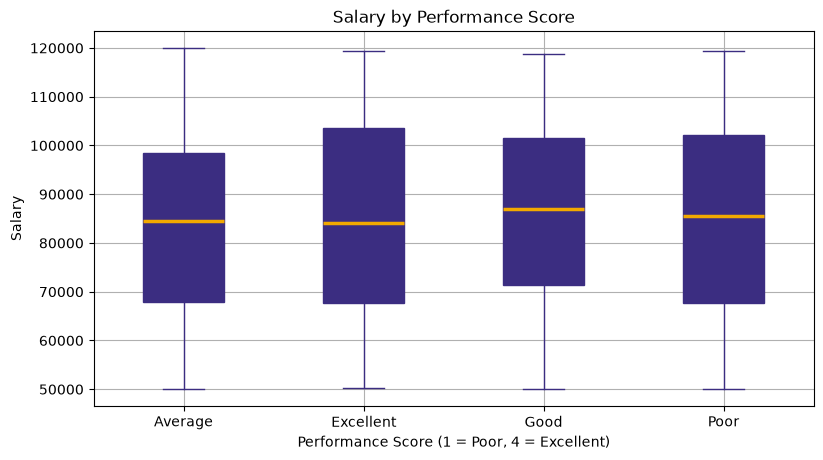

In [566]:
df.boxplot(column="Salary", by="Performance_Score", grid=True, figsize=(9, 5),
           patch_artist=True,
           boxprops=dict(facecolor="#3B2D81", color="#3B2D81"),
           medianprops=dict(color="#F2A900", linewidth=2.5),
           whiskerprops=dict(color="#3B2D81"),
           capprops=dict(color="#3B2D81"))
plt.suptitle("")
plt.title("Salary by Performance Score")
plt.xlabel("Performance Score (1 = Poor, 4 = Excellent)")
plt.ylabel("Salary")
plt.show()

In [567]:
## 2. Cleaning

In [568]:
print(df["Status"].value_counts())
print(df["Performance_Score"].value_counts())
print(df["Remote_Work"].value_counts())
print(df["Department_Region"].unique()[:20])
print(df["Join_Date"].head(10).tolist())
print(df[["Age", "Salary"]].describe())

Status
Pending     356
Active      352
Inactive    312
Name: count, dtype: int64
Performance_Score
Good         270
Average      267
Excellent    267
Poor         216
Name: count, dtype: int64
Remote_Work
True     513
False    507
Name: count, dtype: int64
<StringArray>
[  'DevOps-California',       'Finance-Texas',        'Admin-Nevada',
  'Cloud Tech-Florida',         'Sales-Texas',     'DevOps-New York',
 'Cloud Tech-New York',         'HR-New York',  'Finance-California',
       'Sales-Florida',     'DevOps-Illinois',   'Cloud Tech-Nevada',
      'Admin-Illinois', 'Cloud Tech-Illinois',      'Sales-Illinois',
      'Finance-Nevada',         'Admin-Texas',      'Sales-New York',
     'Finance-Florida',    'Admin-California']
Length: 20, dtype: str
['4/2/2021', '7/10/2020', '12/7/2023', '11/27/2021', '1/5/2022', '6/10/2020', '4/3/2020', '7/17/2022', '12/8/2023', '8/4/2022']
              Age         Salary
count  809.000000     996.000000
mean    32.484549   85155.056396
std      5.6

In [569]:
df = df.dropna(subset=["Salary"])
print(df.shape)                     

(996, 12)


In [570]:
print(df.isna().sum())

Employee_ID            0
First_Name             0
Last_Name              0
Age                  209
Department_Region      0
Status                 0
Join_Date              0
Salary                 0
Email                  0
Phone                  0
Performance_Score      0
Remote_Work            0
dtype: int64


In [571]:

print("Before:", df.shape)
df = df.drop(columns=["Employee_ID", "First_Name", "Last_Name", "Email", "Phone"])
print("After: ", df.shape)
print(df.columns.tolist())

Before: (996, 12)
After:  (996, 7)
['Age', 'Department_Region', 'Status', 'Join_Date', 'Salary', 'Performance_Score', 'Remote_Work']


In [572]:
## Feature Engineering 
print("Before:", df["Department_Region"].unique()[:5])

df[["Department", "Region"]] = df["Department_Region"].str.split("-", n=1, expand=True)
df = df.drop(columns=["Department_Region"])

print("After: ", df[["Department", "Region"]].head())
print(df["Department"].unique())
print(df["Region"].unique())

Before: <StringArray>
[ 'DevOps-California',      'Finance-Texas',       'Admin-Nevada',
 'Cloud Tech-Florida',        'Sales-Texas']
Length: 5, dtype: str
After:     Department      Region
0      DevOps  California
1     Finance       Texas
2       Admin      Nevada
3       Admin      Nevada
4  Cloud Tech     Florida
<StringArray>
['DevOps', 'Finance', 'Admin', 'Cloud Tech', 'Sales', 'HR']
Length: 6, dtype: str
<StringArray>
['California', 'Texas', 'Nevada', 'Florida', 'New York', 'Illinois']
Length: 6, dtype: str


In [573]:
print("Before:", df["Join_Date"].dtype, df["Join_Date"].iloc[0])

df["Join_Date"] = pd.to_datetime(df["Join_Date"], format="%m/%d/%Y")

print("After: ", df["Join_Date"].dtype, df["Join_Date"].iloc[0])
print(df["Join_Date"].min(), "->", df["Join_Date"].max())


Before: str 4/2/2021
After:  datetime64[us] 2021-04-02 00:00:00
2020-01-01 00:00:00 -> 2024-12-29 00:00:00


In [574]:
## 3. Encoding

In [575]:
#ORDENAL
order = {"Poor": 1, "Average": 2, "Good": 3, "Excellent": 4}
df["Performance_Score"] = df["Performance_Score"].map(order)


In [576]:
#One-Hot
df = pd.get_dummies(df, columns=["Status"], dtype=int)
df.filter(like="Status").head()

,Status_Active,Status_Inactive,Status_Pending
0,1,0,0
1,1,0,0
2,0,0,1
3,0,1,0
4,1,0,0


In [577]:
df.columns.tolist()

['Age',
 'Join_Date',
 'Salary',
 'Performance_Score',
 'Remote_Work',
 'Department',
 'Region',
 'Status_Active',
 'Status_Inactive',
 'Status_Pending']

In [578]:
df["Remote_Work"] = df["Remote_Work"].astype(int)
df[["Remote_Work"]].head()

,Remote_Work
0,1
1,1
2,1
3,1
4,0


In [579]:
pd.concat([df["Region"], pd.get_dummies(df["Region"], dtype=int)], axis=1).head()

,Region,California,Florida,Illinois,Nevada,New York,Texas
0,California,1,0,0,0,0,0
1,Texas,0,0,0,0,0,1
2,Nevada,0,0,0,1,0,0
3,Nevada,0,0,0,1,0,0
4,Florida,0,1,0,0,0,0


In [580]:
pd.concat([df["Department"], pd.get_dummies(df["Department"], dtype=int)], axis=1).head()

,Department,Admin,Cloud Tech,DevOps,Finance,HR,Sales
0,DevOps,0,0,1,0,0,0
1,Finance,0,0,0,1,0,0
2,Admin,1,0,0,0,0,0
3,Admin,1,0,0,0,0,0
4,Cloud Tech,0,1,0,0,0,0


In [581]:
df = pd.get_dummies(df, columns=["Department", "Region"], dtype=int)

In [582]:
print(df.shape)
print(df.columns.tolist())

(996, 20)
['Age', 'Join_Date', 'Salary', 'Performance_Score', 'Remote_Work', 'Status_Active', 'Status_Inactive', 'Status_Pending', 'Department_Admin', 'Department_Cloud Tech', 'Department_DevOps', 'Department_Finance', 'Department_HR', 'Department_Sales', 'Region_California', 'Region_Florida', 'Region_Illinois', 'Region_Nevada', 'Region_New York', 'Region_Texas']


In [583]:

## 4. Split

In [584]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Salary", "Join_Date"])
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(796, 18) (200, 18)


In [585]:
median_age = X_train["Age"].median()
print("Missing before:", X_train["Age"].isna().sum(), X_test["Age"].isna().sum())

X_train["Age"] = X_train["Age"].fillna(median_age)
X_test["Age"] = X_test["Age"].fillna(median_age)

print("Missing after: ", X_train["Age"].isna().sum(), X_test["Age"].isna().sum())
print("median:", median_age)

Missing before: 166 43
Missing after:  0 0
median: 30.0


In [586]:
q1 = X_train["Age"].quantile(0.25)
q3 = X_train["Age"].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

print("limits:", low, high)
print("above:", (X_train["Age"] > high).sum(), "| below:", (X_train["Age"] < low).sum())

limits: 22.5 42.5
above: 0 | below: 0


In [587]:
q1 = y_train.quantile(0.25)
q3 = y_train.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

print("limits:", low, high)
print("above:", (y_train > high).sum(), "| below:", (y_train < low).sum())

limits: 19596.202499999985 149800.7225
above: 0 | below: 0


In [588]:
## 5 Scaling 

In [589]:
from sklearn.preprocessing import StandardScaler

num_cols = ["Age"]
print(X_train[num_cols].describe().loc[["mean", "std"]])     # قبل

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(X_train[num_cols].describe().loc[["mean", "std"]])     # بعد

            Age
mean  31.853015
std    5.089365
               Age
mean -1.785283e-17
std   1.000629e+00


In [590]:
## 6. Feature Engineering 

In [591]:
ref_date = pd.Timestamp("2025-01-01")
years = (ref_date - df["Join_Date"]).dt.days / 365.25

X_train["years_of_service"] = years.loc[X_train.index]
X_test["years_of_service"] = years.loc[X_test.index]

print("correlation with Salary:", X_train["years_of_service"].corr(y_train))

correlation with Salary: 0.015419604796840361
